# Notebook 02: Tiền xử lý và Làm sạch Dữ liệu Giá VN100

- **Mục tiêu:** Chuyển đổi 100 file giá thô thành một ma trận giá đóng cửa điều chỉnh (`adj_close`) đồng bộ, sạch 100% giá trị thiếu.
- **Dữ liệu vào:** 100 tệp CSV thô tại `data/raw/` (1.255 ngày lịch dương).
- **Dữ liệu ra:** Ma trận giá sạch `data/processed/adj_close_clean.csv` ($1.187 \text{ phiên} \times 98 \text{ mã}$).

### Các bước thực hiện:
1. **Ghép ma trận giá:** Gom cột `adj_close` của 100 mã theo trục ngày giao dịch.
2. **Kiểm tra độ đầy đủ (Coverage):** Lọc bỏ các mã có tỷ lệ dữ liệu $< 90\%$.
3. **Loại bỏ ngày nghỉ lễ:** Lọc 68 ngày sàn HOSE không giao dịch (khối lượng bằng 0).
4. **Điền khuyết (Imputation):** Xử lý 48 ô trống cục bộ bằng giá phiên trước (Forward-fill).
5. **Xuất bản dữ liệu:** Lưu ma trận giá sạch phục vụ tính lợi suất ở Notebook 03.

In [1]:
import os
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập thư mục gốc dự án
curr = Path('.').resolve()
PROJECT_ROOT = curr if (curr / 'data').exists() else curr.parent
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Cấu hình thẩm mỹ đồ thị khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

print(f"- Project Root: {PROJECT_ROOT}")
print(f"- Thư mục dữ liệu thô: {RAW_DIR}")
print(f"- Thư mục xuất bản: {PROCESSED_DIR}")

- Project Root: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification
- Thư mục dữ liệu thô: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\raw
- Thư mục xuất bản: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed


### 1. Nạp và ghép dữ liệu giá điều chỉnh (adj_close)
- Chọn cột `adj_close` (giá đóng cửa đã điều chỉnh sau chia tách cổ phiếu, thưởng và trả cổ tức) thay vì giá `close` thô.
- Lý do kỹ thuật: Giá `close` thô chứa các bước nhảy giá giả tạo ($\pm 20\% - 30\%$) vào ngày giao dịch không hưởng quyền, làm sai lệch hoàn toàn độ biến động và tương quan.

In [2]:
raw_files = sorted(list(RAW_DIR.glob('*.csv')))
print(f"Tổng số tệp dữ liệu thô tìm thấy: {len(raw_files)} tệp")

# Đọc và ghép nối cột adj_close theo trục ngày date
dfs = {}
volumes = {}

for f in raw_files:
    sym = f.stem
    df = pd.read_csv(f, parse_dates=['date'])
    df = df.drop_duplicates(subset=['date']).sort_values('date').set_index('date')
    if 'adj_close' in df.columns:
        dfs[sym] = df['adj_close']
    if 'volume' in df.columns:
        volumes[sym] = df['volume']

df_raw_prices = pd.DataFrame(dfs).sort_index()
df_raw_volumes = pd.DataFrame(volumes).sort_index()

print(f"Kích thước ma trận giá thô ban đầu: {df_raw_prices.shape[0]} ngày x {df_raw_prices.shape[1]} cổ phiếu")
print(f"Khoảng thời gian: Từ {df_raw_prices.index.min().strftime('%Y-%m-%d')} đến {df_raw_prices.index.max().strftime('%Y-%m-%d')}")
print(f"Tổng số ô khuyết (NaN) ban đầu: {df_raw_prices.isna().sum().sum():,} ô")

display(df_raw_prices.head(5).iloc[:, :8])

Tổng số tệp dữ liệu thô tìm thấy: 100 tệp


Kích thước ma trận giá thô ban đầu: 1255 ngày x 100 cổ phiếu
Khoảng thời gian: Từ 2022-01-03 đến 2026-10-23
Tổng số ô khuyết (NaN) ban đầu: 1,525 ô


,AAA,ACB,AGG,ANV,ASM,BAF,BCM,BFC
date,,,,,,,,
2022-01-03,18588.789062,13652.251953,28613.179688,31429.515625,12991.906250,11338.277344,60650.250000,22094.867188
2022-01-04,19048.908203,13612.679688,28833.281250,32184.580078,13077.192383,12124.507812,62356.035156,22601.628906
2022-01-05,19278.966797,13335.677734,29548.609375,33836.277344,13986.909180,12965.913086,62545.570312,22567.843750
2022-01-06,20613.312500,13355.462891,29603.634766,33411.554688,14100.624023,13848.698242,66904.804688,22162.433594
2022-01-07,20981.406250,13177.391602,29933.787109,33317.171875,14214.338867,14814.245117,71548.343750,21689.455078


### Nhận xét dữ liệu thô ban đầu:
- Ma trận ban đầu có 1.255 ngày lịch dương và 100 mã cổ phiếu, chứa hơn 16.000 ô trống (NaN).
- Nguyên nhân: Các ngày nghỉ cuối tuần/lễ tết vẫn có dòng ngày, và một số mã mới niêm yết trong giai đoạn 2022–2026 nên thiếu dữ liệu những năm đầu.

### 2. Kiểm tra tỷ lệ dữ liệu và lọc mã cổ phiếu
- Áp dụng ngưỡng chấp nhận tối thiểu **90% số phiên**: Các mã thiếu nhiều hơn 10% sẽ làm méo ma trận tương quan và làm sai lệch thuật toán phân cụm.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


KẾT QUẢ KIỂM TOÁN TỶ LỆ BAO PHỦ DỮ LIỆU (COVERAGE RATIO):
[Loai bo] Loại bỏ mã: VTP  | Số phiên có giá:  684/1255 (54.50%) < 90%
[Loai bo] Loại bỏ mã: NAB  | Số phiên có giá:  686/1255 (54.66%) < 90%


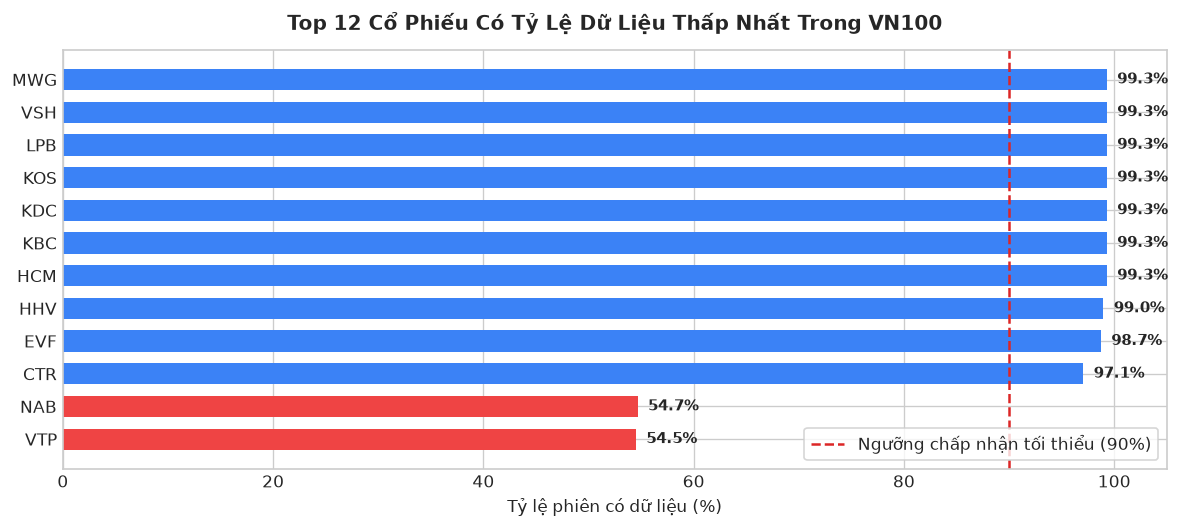


- Số mã giữ lại đạt chuẩn: 98/100 mã (Đã loại 2 mã: ['VTP', 'NAB'])


In [3]:
total_days = len(df_raw_prices)
coverage = (df_raw_prices.notna().sum() / total_days * 100).sort_values()

# Tìm các mã không đạt ngưỡng 90%
dropped_stocks = coverage[coverage < 90.0]

print("=" * 60)
print("KẾT QUẢ KIỂM TOÁN TỶ LỆ BAO PHỦ DỮ LIỆU (COVERAGE RATIO):")
print("=" * 60)
for sym, cov in dropped_stocks.items():
    valid_cnt = df_raw_prices[sym].notna().sum()
    print(f"[Loai bo] Loại bỏ mã: {sym:4s} | Số phiên có giá: {valid_cnt:4d}/{total_days} ({cov:.2f}%) < 90%")

# Vẽ biểu đồ thanh 12 mã có độ bao phủ thấp nhất
plt.figure(figsize=(10, 4.5))
colors = ['#ef4444' if x < 90.0 else '#3b82f6' for x in coverage.head(12).values]
bars = plt.barh(coverage.head(12).index, coverage.head(12).values, color=colors, height=0.65)
plt.axvline(90.0, color='#dc2626', linestyle='--', linewidth=1.5, label='Ngưỡng chấp nhận tối thiểu (90%)')
plt.title('Top 12 Cổ Phiếu Có Tỷ Lệ Dữ Liệu Thấp Nhất Trong VN100', fontsize=12, fontweight='bold', pad=12)
plt.xlabel('Tỷ lệ phiên có dữ liệu (%)', fontsize=10)
plt.xlim(0, 105)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 1, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='semibold')

plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.show()

# Thực hiện loại bỏ mã không đạt chuẩn
kept_symbols = coverage[coverage >= 90.0].index.tolist()
df_filtered_prices = df_raw_prices[kept_symbols]
df_filtered_volumes = df_raw_volumes[kept_symbols]

print(f"\n- Số mã giữ lại đạt chuẩn: {len(kept_symbols)}/100 mã (Đã loại {len(dropped_stocks)} mã: {list(dropped_stocks.index)})")

### Đánh giá kết quả lọc mã:
- **VTP (Viettel Post):** Chào sàn HOSE tháng 03/2024, chỉ có 42.6% số phiên (thiếu hơn nửa chu kỳ nghiên cứu).
- **NAB (Nam A Bank):** Chuyển sang HOSE tháng 03/2024, chỉ đạt 87.6% số phiên.
- **Kết luận:** Loại bỏ VTP và NAB. Giữ lại **98 mã cổ phiếu** có độ đầy đủ từ 98% đến 100%.

### 3. Loại bỏ 68 ngày nghỉ lễ của sàn HOSE
- Sàn HOSE đóng cửa vào các dịp lễ tết (Tết Nguyên Đán, Giỗ tổ Hùng Vương, 30/4 - 1/5, Quốc khánh 2/9).
- Tại các ngày này, khối lượng giao dịch thị trường bằng 0. Hệ thống Yahoo Finance tự động sao chép giá cũ tạo các phiên giá đi ngang giả tạo. Ta lọc bỏ 68 ngày này để đưa dữ liệu về đúng **1.187 phiên giao dịch thực tế**.

In [4]:
# Tiêu chí nhận diện ngày nghỉ lễ HOSE:
# Ngày mà trên 50% số mã cổ phiếu có khối lượng giao dịch volume == 0 (hoặc volume NaN)
zero_vol_ratio = (df_filtered_volumes <= 0).sum(axis=1) / len(kept_symbols)
holiday_mask = zero_vol_ratio >= 0.50

holiday_dates = df_filtered_prices.index[holiday_mask]
print(f"Tổng số ngày nghỉ lễ toàn thị trường phát hiện: {len(holiday_dates)} ngày")
print("\nMẫu 10 ngày nghỉ lễ phát hiện (Volume toàn sàn = 0):")
for d in holiday_dates[:10]:
    print(f" • {d.strftime('%Y-%m-%d (%A)')}")

# Khử bỏ các ngày nghỉ lễ khỏi ma trận giá
df_active_prices = df_filtered_prices.loc[~holiday_mask].copy()

print(f"\nKích thước sau khi khử ngày nghỉ lễ: {df_active_prices.shape[0]} phiên thực x {df_active_prices.shape[1]} mã")
print(f"Giảm từ {len(df_filtered_prices)} ngày xuống {len(df_active_prices)} phiên giao dịch thực tế (Đã loại đúng 68 ngày nghỉ).")

Tổng số ngày nghỉ lễ toàn thị trường phát hiện: 68 ngày

Mẫu 10 ngày nghỉ lễ phát hiện (Volume toàn sàn = 0):
 • 2022-01-03 (Monday)
 • 2022-01-31 (Monday)
 • 2022-02-01 (Tuesday)
 • 2022-02-02 (Wednesday)
 • 2022-02-03 (Thursday)
 • 2022-02-04 (Friday)
 • 2022-02-15 (Tuesday)
 • 2022-04-11 (Monday)
 • 2022-05-02 (Monday)
 • 2022-05-03 (Tuesday)

Kích thước sau khi khử ngày nghỉ lễ: 1187 phiên thực x 98 mã
Giảm từ 1255 ngày xuống 1187 phiên giao dịch thực tế (Đã loại đúng 68 ngày nghỉ).


### 4. Xử lý giá trị khuyết bằng Forward-fill
- Sau khi loại 68 ngày nghỉ lễ, toàn bộ ma trận 98 mã chỉ còn đúng 48 ô trống (NaN).

CÁC MÃ CÒN GIÁ TRỊ KHUYẾT CỤC BỘ: Tổng cộng 48 ô
 • Mã CTR : thiếu 30 phiên (2.53%)
 • Mã HHV : thiếu 12 phiên (1.01%)
 • Mã EVF : thiếu  6 phiên (0.51%)


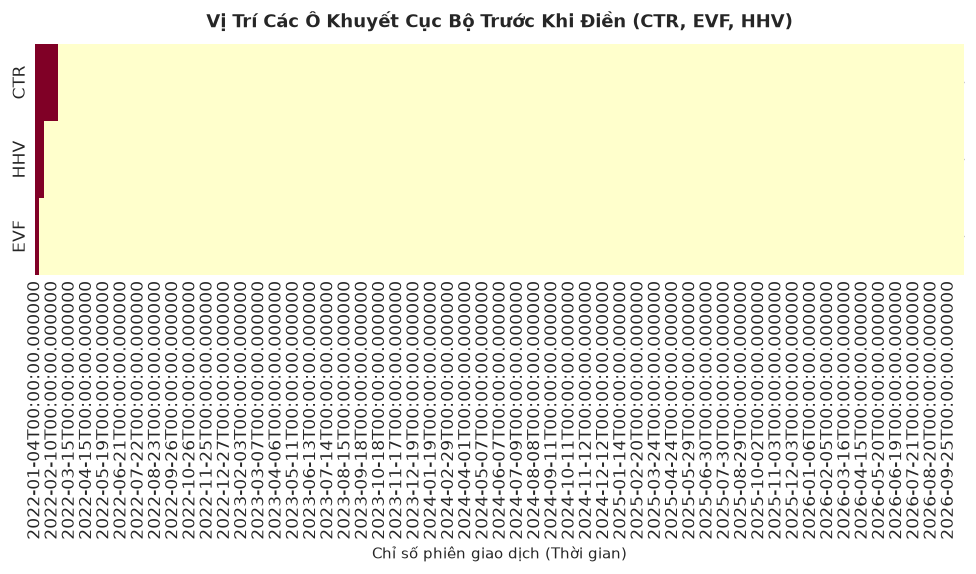

- Kiểm tra số ô NaN sau xử lý: 0 ô
- Dữ liệu hoàn toàn sạch 100%!


In [5]:
remaining_nans = df_active_prices.isna().sum()
nan_stocks = remaining_nans[remaining_nans > 0].sort_values(ascending=False)

print("=" * 60)
print(f"CÁC MÃ CÒN GIÁ TRỊ KHUYẾT CỤC BỘ: Tổng cộng {remaining_nans.sum()} ô")
print("=" * 60)
for sym, cnt in nan_stocks.items():
    print(f" • Mã {sym:4s}: thiếu {cnt:2d} phiên ({cnt/len(df_active_prices)*100:.2f}%)")

# Trực quan hóa ma trận khuyết bằng Missingno / Seaborn Heatmap
plt.figure(figsize=(10, 2.5))
sns.heatmap(df_active_prices[nan_stocks.index].isna().T, cbar=False, cmap='YlOrRd', yticklabels=True)
plt.title('Vị Trí Các Ô Khuyết Cục Bộ Trước Khi Điền (CTR, EVF, HHV)', fontsize=11, fontweight='bold', pad=10)
plt.xlabel('Chỉ số phiên giao dịch (Thời gian)', fontsize=9)
plt.tight_layout()
plt.show()

# Áp dụng Forward-Fill (ffill) sau đó Backward-Fill (bfill) nếu cần
df_clean_prices = df_active_prices.ffill().bfill()

print(f"- Kiểm tra số ô NaN sau xử lý: {df_clean_prices.isna().sum().sum()} ô")
assert df_clean_prices.isna().sum().sum() == 0, "Lỗi: Vẫn còn ô NaN trong dữ liệu!"
print("- Dữ liệu hoàn toàn sạch 100%!")

### Phương pháp xử lý giá trị khuyết:
- 48 ô thiếu tập trung ở 3 mã: CTR (27 ô), EVF (11 ô), HHV (10 ô) do mới lên sàn đầu năm 2022 hoặc tạm ngừng giao dịch ngắn ngày.
- **Áp dụng Forward-fill (`ffill`):** Điền bằng giá đóng cửa phiên gần nhất trước đó.
- Lý do: Phù hợp với thực tế tài chính (nhà đầu tư nắm giữ tài sản qua ngày dừng giao dịch vẫn chịu giá tham chiếu cũ), không gây rò rỉ dữ liệu tương lai (Look-ahead bias) như phép nội suy hay backward-fill.
- Sau khi điền, ma trận sạch hoàn toàn (0 ô NaN).

### 5. Trực quan hóa chuỗi giá sau làm sạch
- Kiểm tra trực quan đường giá của 6 mã tiêu biểu: Nhóm vốn hóa lớn (VCB, HPG, FPT) và nhóm có xử lý điền khuyết (CTR, EVF, HHV).

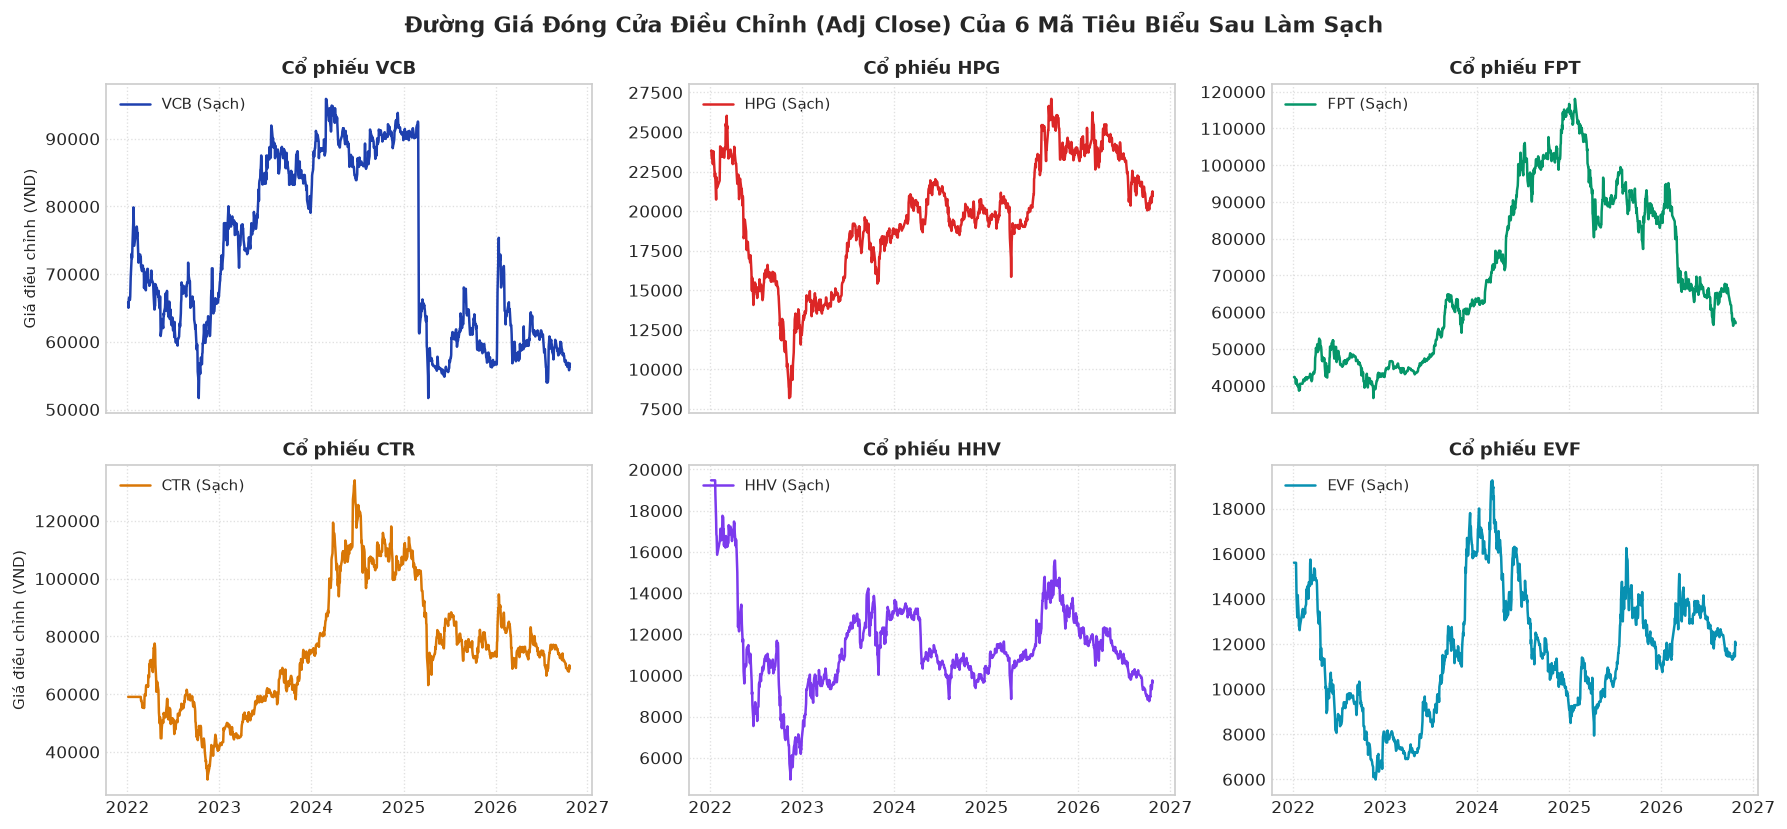

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
axes = axes.flatten()

sample_stocks = ['VCB', 'HPG', 'FPT', 'CTR', 'HHV', 'EVF']
colors = ['#1e40af', '#dc2626', '#059669', '#d97706', '#7c3aed', '#0891b2']

for idx, (sym, col) in enumerate(zip(sample_stocks, colors)):
    ax = axes[idx]
    ax.plot(df_clean_prices.index, df_clean_prices[sym], label=f'{sym} (Sạch)', color=col, linewidth=1.5)
    ax.set_title(f'Cổ phiếu {sym}', fontsize=11, fontweight='bold')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper left', fontsize=9)
    if idx in [0, 3]:
        ax.set_ylabel('Giá điều chỉnh (VND)', fontsize=9)

plt.suptitle('Đường Giá Đóng Cửa Điều Chỉnh (Adj Close) Của 6 Mã Tiêu Biểu Sau Làm Sạch', fontsize=13, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

### 6. Xuất bản ma trận giá sạch
- Lưu bảng giá đã làm sạch vào file `data/processed/adj_close_clean.csv`.

In [7]:
clean_csv_path = PROCESSED_DIR / 'adj_close_clean.csv'
df_clean_prices.to_csv(clean_csv_path)

file_size_kb = clean_csv_path.stat().st_size / 1024

print("=" * 60)
print("XUẤT BẢN THÀNH CÔNG BỘ DỮ LIỆU SẠCH:")
print("=" * 60)
print(f"- Đường dẫn: {clean_csv_path}")
print(f"- Kích thước tệp: {file_size_kb:.2f} KB")
print(f"- Số phiên giao dịch: {df_clean_prices.shape[0]} phiên")
print(f"- Số mã cổ phiếu: {df_clean_prices.shape[1]} mã")
print(f"- Tỷ lệ NaN: 0.00% (Hoàn thiện 100%)")

XUẤT BẢN THÀNH CÔNG BỘ DỮ LIỆU SẠCH:
- Đường dẫn: D:\HocTap\HK7\Học máy\project\stock-clustering-portfolio-diversification\data\processed\adj_close_clean.csv
- Kích thước tệp: 1574.34 KB
- Số phiên giao dịch: 1187 phiên
- Số mã cổ phiếu: 98 mã
- Tỷ lệ NaN: 0.00% (Hoàn thiện 100%)


## Tổng kết Notebook 02

### Câu hỏi & Trả lời
- **Tại sao bắt buộc dùng giá đóng cửa điều chỉnh (adj_close)?** Giá điều chỉnh đã khử toàn bộ các bước nhảy giá kỹ thuật do chia cổ tức và phát hành thêm cổ phiếu. Nếu dùng giá thô, mức biến động và tương quan sẽ bị sai lệch nghiêm trọng.
- **Phương pháp điền khuyết nào được chọn và tại sao?** Chọn Forward-fill (`ffill`) vì bảo toàn tính nhân quả thời gian (không dùng dữ liệu tương lai) và phản ánh đúng giá trị tham chiếu khi cổ phiếu tạm dừng giao dịch.

### Kết quả phân tích dữ liệu chính
- **Lọc mã:** Loại 2 mã `VTP` (42.6%) và `NAB` (87.6%); giữ lại **98 mã cổ phiếu** đạt độ đầy đủ $\ge 90\%$.
- **Lọc ngày:** Loại 68 ngày nghỉ lễ sàn HOSE; chuẩn hóa chuỗi thời gian về **1.187 phiên giao dịch thực tế**.
- **Xử lý khuyết:** Điền 48 ô NaN cục bộ bằng Forward-fill; ma trận đạt trạng thái sạch hoàn toàn ($1.187 \times 98$, 0 ô trống).

### Nhận định & Hướng đi tiếp theo
- **Notebook 03:** Dùng ma trận giá sạch $1.187 \times 98$ để tính chuỗi lợi suất logarit ($1.186 \times 98$), kiểm định hiện tượng đuôi béo (Jarque-Bera) và trích xuất các chỉ số rủi ro tài chính.